<a href="https://colab.research.google.com/github/Epot12/DLA_Lab3/blob/master/Lab3_Transformers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Working with Transformers in the HuggingFace Ecosystem

In this laboratory exercise we will learn how to work with the HuggingFace ecosystem to adapt models to new tasks. As you will see, much of what is required is *investigation* into the inner-workings of the HuggingFace abstractions. With a little work, a little trial-and-error, it is fairly easy to get a working adaptation pipeline up and running.

### Exercise 1: Sentiment Analysis (warm up)

In this first exercise we will start from a pre-trained BERT transformer and build up a model able to perform text sentiment analysis. Transformers are complex beasts, so we will build up our pipeline in several explorative and incremental steps.

#### Exercise 1.1: Dataset Splits and Pre-trained model
There are a many sentiment analysis datasets, but we will use one of the smallest ones available: the [Cornell Rotten Tomatoes movie review dataset](cornell-movie-review-data/rotten_tomatoes), which consists of 5,331 positive and 5,331 negative processed sentences from the Rotten Tomatoes movie reviews.

**Your first task**: Load the dataset and figure out what splits are available and how to get them. Spend some time exploring the dataset to see how it is organized. Note that we will be using the [HuggingFace Datasets](https://huggingface.co/docs/datasets/en/index) library for downloading, accessing, splitting, and batching data for training and evaluation.

In [1]:
from datasets import load_dataset, get_dataset_split_names

# Your code here.
ds_id = 'cornell-movie-review-data/rotten_tomatoes'
get_dataset_split_names(ds_id)

ds_train = load_dataset(ds_id, split='train')
ds_val = load_dataset(ds_id, split='validation')
ds_test = load_dataset(ds_id, split='test')


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

train.parquet:   0%|          | 0.00/699k [00:00<?, ?B/s]

validation.parquet:   0%|          | 0.00/90.0k [00:00<?, ?B/s]

test.parquet:   0%|          | 0.00/92.2k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/8530 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1066 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1066 [00:00<?, ? examples/s]

In [2]:
print(f"split di cornell-movie-review-data/rotten_tomatoes: {get_dataset_split_names(ds_id)}")

split di cornell-movie-review-data/rotten_tomatoes: ['train', 'validation', 'test']


#### Exercise 1.2: A Pre-trained BERT and Tokenizer

The model we will use is a *very* small BERT transformer called [Distilbert](https://huggingface.co/distilbert/distilbert-base-uncased) this model was trained (using self-supervised learning) on the same corpus as BERT but using the full BERT base model as a *teacher*.

**Your next task**: Load the Distilbert model and corresponding tokenizer. Use the tokenizer on a few samples from the dataset and pass the tokens through the model to see what outputs are provided. I suggest you use the [`AutoModel`](https://huggingface.co/transformers/v3.0.2/model_doc/auto.html) class (and the `from_pretrained()` method) to load the model and `AutoTokenizer` to load the tokenizer).

In [2]:
from transformers import AutoTokenizer, AutoModel

# Your code here.
bert_id = 'distilbert-base-uncased'
tokenizer = AutoTokenizer.from_pretrained(bert_id)
distil_bert = AutoModel.from_pretrained(bert_id)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

In [4]:
samples = ds_train['text'][:2] #samples da passare nel modello
print(f"samples: {samples}")

samples: ['the rock is destined to be the 21st century\'s new " conan " and that he\'s going to make a splash even greater than arnold schwarzenegger , jean-claud van damme or steven segal .', 'the gorgeously elaborate continuation of " the lord of the rings " trilogy is so huge that a column of words cannot adequately describe co-writer/director peter jackson\'s expanded vision of j . r . r . tolkien\'s middle-earth .']


In [5]:
inputs = tokenizer(samples, padding=True, truncation=True, return_tensors="pt")
print(f"inputs post tokenizer: {inputs}")

inputs post tokenizer: {'input_ids': tensor([[  101,  1996,  2600,  2003, 16036,  2000,  2022,  1996,  7398,  2301,
          1005,  1055,  2047,  1000, 16608,  1000,  1998,  2008,  2002,  1005,
          1055,  2183,  2000,  2191,  1037, 17624,  2130,  3618,  2084,  7779,
         29058,  8625, 13327,  1010,  3744,  1011, 18856, 19513,  3158,  5477,
          4168,  2030,  7112, 16562,  2140,  1012,   102,     0,     0,     0,
             0,     0],
        [  101,  1996,  9882,  2135,  9603, 13633,  1997,  1000,  1996,  2935,
          1997,  1996,  7635,  1000, 11544,  2003,  2061,  4121,  2008,  1037,
          5930,  1997,  2616,  3685, 23613,  6235,  2522,  1011,  3213,  1013,
          2472,  2848,  4027,  1005,  1055,  4423,  4432,  1997,  1046,  1012,
          1054,  1012,  1054,  1012, 23602,  1005,  1055,  2690,  1011,  3011,
          1012,   102]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1, 1, 

In [3]:
outputs = distil_bert(**inputs)

NameError: name 'inputs' is not defined

In [7]:
print("\nTipo di output:", type(outputs))
print("Shape dell'ultimo stato nascosto:", outputs.last_hidden_state.shape)


Tipo di output: <class 'transformers.modeling_outputs.BaseModelOutput'>
Shape dell'ultimo stato nascosto: torch.Size([2, 52, 768])


In [8]:
print(f"output del modello per il primo esempio: {outputs.last_hidden_state[0]}")

output del modello per il primo esempio: tensor([[-0.0332, -0.0168,  0.0194,  ...,  0.0476,  0.5834,  0.3036],
        [-0.0235, -0.0555, -0.3638,  ...,  0.1877,  0.5781, -0.1577],
        [-0.0516, -0.1014, -0.1511,  ...,  0.1503,  0.2649, -0.1575],
        ...,
        [ 0.3688, -0.1147,  0.8428,  ..., -0.0708, -0.0178, -0.2516],
        [ 0.0654, -0.0206,  0.1889,  ...,  0.1159,  0.2323, -0.2404],
        [ 0.0373, -0.0104,  0.1203,  ...,  0.1049,  0.2852, -0.3035]],
       grad_fn=<SelectBackward0>)


#### Exercise 1.3: A Stable Baseline

In this exercise I want you to:
1. Use Distilbert as a *feature extractor* to extract representations of the text strings from the dataset splits;
2. Train a classifier (your choice, by an SVM from Scikit-learn is an easy choice).
3. Evaluate performance on the validation and test splits.

These results are our *stable baseline* -- the **starting** point on which we will (hopefully) improve in the next exercise.

**Hint**: There are a number of ways to implement the feature extractor, but probably the best is to use a [feature extraction `pipeline`](https://huggingface.co/tasks/feature-extraction). You will need to interpret the output of the pipeline and extract only the `[CLS]` token from the *last* transformer layer. *How can you figure out which output that is?*

TODO: decidere se cambiare l'implementazione e usare una pipeline come richiesto dal comando invece che fare tutto manualmente come nell'implementazione attuale.

In [6]:
import torch

In [7]:
# Your code here.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Sto usando il dispositivo: {device}")

def tokenize(batch):
    return tokenizer(batch["text"], padding=True, truncation=True)

dataset = load_dataset(ds_id)

dataset_encoded = dataset.map(tokenize, batched=True, batch_size=None)

print("Colonne del dataset:", dataset_encoded.column_names)

Sto usando il dispositivo: cuda


Map:   0%|          | 0/8530 [00:00<?, ? examples/s]

Map:   0%|          | 0/1066 [00:00<?, ? examples/s]

Map:   0%|          | 0/1066 [00:00<?, ? examples/s]

Colonne del dataset: {'train': ['text', 'label', 'input_ids', 'attention_mask'], 'validation': ['text', 'label', 'input_ids', 'attention_mask'], 'test': ['text', 'label', 'input_ids', 'attention_mask']}


In [11]:
dataset_encoded.set_format("torch", columns=["input_ids", "attention_mask", "label"])
model_d_bert = distil_bert.to(device)

In [12]:
def extract_hidden_states(batch):
    inputs = {k: v.to(device) for k, v in batch.items()
              if k in tokenizer.model_input_names}

    with torch.no_grad():
        last_hidden_state = model_d_bert(**inputs).last_hidden_state

    return {"hidden_state": last_hidden_state[:, 0].cpu().numpy()}

In [13]:
dataset_hidden = dataset_encoded.map(extract_hidden_states, batched=True)

Map:   0%|          | 0/8530 [00:00<?, ? examples/s]

Map:   0%|          | 0/1066 [00:00<?, ? examples/s]

Map:   0%|          | 0/1066 [00:00<?, ? examples/s]

In [14]:
print("Nuove colonne:", dataset_hidden.column_names)

Nuove colonne: {'train': ['text', 'label', 'input_ids', 'attention_mask', 'hidden_state'], 'validation': ['text', 'label', 'input_ids', 'attention_mask', 'hidden_state'], 'test': ['text', 'label', 'input_ids', 'attention_mask', 'hidden_state']}


In [15]:
print(dataset_hidden)

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask', 'hidden_state'],
        num_rows: 8530
    })
    validation: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask', 'hidden_state'],
        num_rows: 1066
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask', 'hidden_state'],
        num_rows: 1066
    })
})


In [16]:
import numpy as np

In [17]:
X_train = np.array(dataset_hidden["train"]["hidden_state"])
y_train = np.array(dataset_hidden["train"]["label"])

print(f"Dimensioni Features Train: {X_train.shape}")

Dimensioni Features Train: (8530, 768)


In [18]:
print("Preparazione dei dati di validazione")
X_val = np.array(dataset_hidden["validation"]["hidden_state"])
y_val = np.array(dataset_hidden["validation"]["label"])

print(f"Dimensioni Training: X={X_train.shape}, y={y_train.shape}")
print(f"Dimensioni Validation: X={X_val.shape}, y={y_val.shape}")

Preparazione dei dati di validazione
Dimensioni Training: X=(8530, 768), y=(8530,)
Dimensioni Validation: X=(1066, 768), y=(1066,)


In [19]:
from sklearn.svm import SVC

svm_clf = SVC(kernel='linear', C=1.0, random_state=42)
svm_clf.fit(X_train, y_train)
score = svm_clf.score(X_val, y_val)
print(f"\nAccuracy sul Validation Set: {score:.2%}")
y_preds = svm_clf.predict(X_val)


Accuracy sul Validation Set: 81.89%


In [20]:
from sklearn import metrics
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

print(classification_report(y_val, y_preds, target_names=["Negativo", "Positivo"]))

              precision    recall  f1-score   support

    Negativo       0.80      0.85      0.82       533
    Positivo       0.84      0.79      0.81       533

    accuracy                           0.82      1066
   macro avg       0.82      0.82      0.82      1066
weighted avg       0.82      0.82      0.82      1066



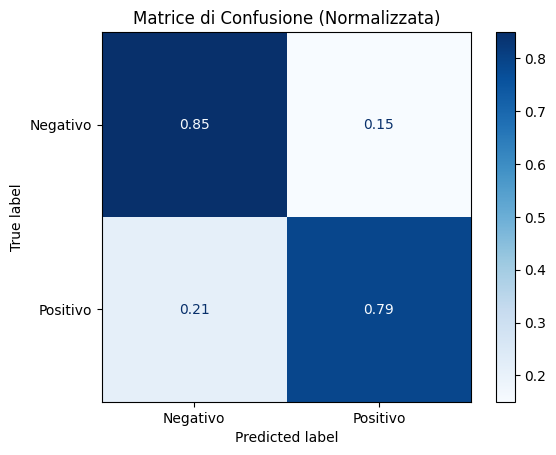

In [21]:
import matplotlib.pyplot as plt

disp = ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_preds,
    display_labels=["Negativo", "Positivo"],
    cmap=plt.cm.Blues,
    normalize='true' # Mostra le percentuali invece dei numeri assoluti
)
plt.title("Matrice di Confusione (Normalizzata)")
plt.show()

-----
### Exercise 2: Fine-tuning Distilbert

In this exercise we will fine-tune the Distilbert model to (hopefully) improve sentiment analysis performance.

#### Exercise 2.1: Token Preprocessing

The first thing we need to do is *tokenize* our dataset splits. Our current datasets return a dictionary with *strings*, but we want *input token ids* (i.e. the output of the tokenizer). This is easy enough to do my hand, but the HugginFace `Dataset` class provides convenient, efficient, and *lazy* methods. See the documentation for [`Dataset.map`](https://huggingface.co/docs/datasets/v3.5.0/en/package_reference/main_classes#datasets.Dataset.map).

**Tip**: Verify that your new datasets are returning for every element: `text`, `label`, `intput_ids`, and `attention_mask`.

In [22]:
# Your code here.
# Itera su tutte le chiavi disponibili (train, validation, test)
for split in dataset_hidden.keys():
    print(f"Colonne nello split '{split}': {dataset_hidden[split].column_names}")

Colonne nello split 'train': ['text', 'label', 'input_ids', 'attention_mask', 'hidden_state']
Colonne nello split 'validation': ['text', 'label', 'input_ids', 'attention_mask', 'hidden_state']
Colonne nello split 'test': ['text', 'label', 'input_ids', 'attention_mask', 'hidden_state']


#### Exercise 2.2: Setting up the Model to be Fine-tuned

In this exercise we need to prepare the base Distilbert model for fine-tuning for a *sequence classification task*. This means, at the very least, appending a new, randomly-initialized classification head connected to the `[CLS]` token of the last transformer layer. Luckily, HuggingFace already provides an `AutoModel` for just this type of instantiation: [`AutoModelForSequenceClassification`](https://huggingface.co/transformers/v3.0.2/model_doc/auto.html#automodelforsequenceclassification). You will want you instantiate one of these for fine-tuning.

In [24]:
from transformers import AutoModelForSequenceClassification

# Your code here.
model_d_bert_ft = AutoModelForSequenceClassification.from_pretrained(bert_id, num_labels=2)
model_d_bert_ft = model_d_bert_ft.to(device)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


#### Exercise 2.3: Fine-tuning Distilbert

Finally. In this exercise you should use a HuggingFace [`Trainer`](https://huggingface.co/docs/transformers/main/en/trainer) to fine-tune your model on the Rotten Tomatoes training split. Setting up the trainer will involve (at least):


1. Instantiating a [`DataCollatorWithPadding`](https://huggingface.co/docs/transformers/en/main_classes/data_collator) object which is what *actually* does your batch construction (by padding all sequences to the same length).
2. Writing an *evaluation function* that will measure the classification accuracy. This function takes a single argument which is a tuple containing `(logits, labels)` which you should use to compute classification accuracy (and maybe other metrics like F1 score, precision, recall) and return a `dict` with these metrics.  
3. Instantiating a [`TrainingArguments`](https://huggingface.co/docs/transformers/v4.51.1/en/main_classes/trainer#transformers.TrainingArguments) object using some reasonable defaults.
4. Instantiating a `Trainer` object using your train and validation splits, you data collator, and function to compute performance metrics.
5. Calling `trainer.train()`, waiting, waiting some more, and then calling `trainer.evaluate()` to see how it did.

**Tip**: When prototyping this laboratory I discovered the HuggingFace [Evaluate library](https://huggingface.co/docs/evaluate/en/index) which provides evaluation metrics. However I found it to have insufferable layers of abstraction and getting actual metrics computed. I suggest just using the Scikit-learn metrics...

In [4]:
# Your code here.
!pip install accelerate --upgrade

In [8]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

def tokenize_basic(batch):
    # Padding=False perché lo farà il DataCollator dinamicamente. Migliora le prestazioni
    return tokenizer(batch["text"], truncation=True)

dataset_basic = dataset.map(tokenize_basic, batched=True)

Map:   0%|          | 0/8530 [00:00<?, ? examples/s]

Map:   0%|          | 0/1066 [00:00<?, ? examples/s]

Map:   0%|          | 0/1066 [00:00<?, ? examples/s]

In [9]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def evaluation(eval_pred):
    metrics = {}
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1) #scikit learn non accetta logits
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, preds, average='binary' #in questo modo si controlla quanto il modello è bravo a trovare la classe positiva perché il Trainer vuole solo un valore ma noi abbiamo
        #due classi
    )
    acc = accuracy_score(labels, preds)
    metrics['accuracy'] = acc
    metrics['precision'] = precision
    metrics['recall'] = recall
    metrics['f1'] = f1
    return metrics


In [10]:
from transformers import TrainingArguments
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [11]:
#TODO: cambiare l'account di weights and biases e fare login con la mail universitaria

import wandb
wandb.login()
import os
os.environ["WANDB_PROJECT"] = "DLA_Lab3"

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice:

 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Find your API key here: https://wandb.ai/authorize
wandb: Paste an API key from your profile and hit enter:

 ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: emi_lore (emi_lore-university-of-florence) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [34]:
# TODO: decidere se anche qui selezionare il miglior modello in base a F1 (dovrebbe essere più robusto) invece che in base all'eval loss (come viene fatto qui e come di default in HF)
# in ogni caso, una volta deciso usare la stessa metrica per tutti i training
training_args_d_bert_ft = TrainingArguments(
    output_dir="/content/drive/MyDrive/DLA_Lab3/DistilBert_FT",          # Cartella dove salvare i checkpoint e il modello finale

    eval_strategy="epoch",           # Valuta il modello sul validation set alla fine di ogni epoca
    save_strategy="epoch",           # Salva un checkpoint del modello alla fine di ogni epoca. eval_strategy e save_strategy devono coincidere. è buona norma
    load_best_model_at_end=True,     # Alla fine del training, ricarica il checkpoint con la loss migliore

    learning_rate=2e-5,              # La velocità di apprendimento (2e-5 è standard per BERT)
    per_device_train_batch_size=16,  # Quante frasi processare insieme
    per_device_eval_batch_size=16,   # Batch size per la validazione
    num_train_epochs=2,              # Quante volte rivedere tutto il dataset (2 o 3 dovrebbero bastare per il fine-tuning)
    weight_decay=0.01,               # Regolarizzazione per evitare l'overfitting

    fp16=True,                       # "Mixed Precision" (dovrebbe essere più veloce su GPU T4 di Colab)
    push_to_hub=False,               # per non caricare online su HuggingFace Hub (salvo solo in locale)
    report_to="wandb",                 # per loggare su weights and biases
    run_name="distilbert-run-1"         #nome di questo specifico esperimento (per wandb)
)

In [19]:
from transformers import Trainer

trainer_d_bert_ft = Trainer(
    model=model_d_bert_ft,          # il modello (AutoModelForSequenceClassification)
    args=training_args_d_bert_ft,             # configurazione per il training (inclusi wandb e output_dir)
    train_dataset=dataset_basic["train"],      # Dataset di training tokenizzato (senza padding statico)
    eval_dataset=dataset_basic["validation"],  # Dataset di validazione
    tokenizer=tokenizer,            # Il tokenizer (serve per salvare il vocab)
    data_collator=data_collator,    # Il collator che fa padding dinamico
    compute_metrics=evaluation
)

NameError: name 'model_d_bert_ft' is not defined

In [36]:
trainer_d_bert_ft.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.205000,0.479584,0.846154,0.825397,0.878049,0.850909
2,0.160300,0.529679,0.857411,0.856075,0.859287,0.857678


TrainOutput(global_step=1068, training_loss=0.18296896741631324, metrics={'train_runtime': 61.0637, 'train_samples_per_second': 279.38, 'train_steps_per_second': 17.49, 'total_flos': 215637261882480.0, 'train_loss': 0.18296896741631324, 'epoch': 2.0})

In [37]:
trainer_d_bert_ft.evaluate()

{'eval_loss': 0.4795839786529541,
 'eval_accuracy': 0.8461538461538461,
 'eval_precision': 0.8253968253968254,
 'eval_recall': 0.8780487804878049,
 'eval_f1': 0.850909090909091,
 'eval_runtime': 1.1005,
 'eval_samples_per_second': 968.632,
 'eval_steps_per_second': 60.88,
 'epoch': 2.0}

I risultati del fine tuning su Distil Bert sono buoni, però si osserva che, alla seconda epoca, inizia a manifestarsi un po' di overfitting, con la validation loss in aumento. Questo è abbastanza normale e, in ogni caso, il salvataggio automatico salva il miglior modello, in questo caso quello risultante dalla prima epoca. Tale modello è sostanzialmente esente da overfitting. Le prestazioni di accuracy sono nel range dello stato dell'arte (82 - 85 %). E' interessante notare come il modello baseline che sfrutta una SVM in output non fa molto peggio (81.89% sul validation set) e ha il pregio di richiedere un training molto più leggero.

####Confronto tra fp16 e fp32

Nel codice precedente ho effettuato il fine tuning di Distil Bert usando mixed precision con numeri floating point a 16 bit, allo scopo di velocizzare le operazioni su GPU. Di seguito riporto un confronto tra il training in fp16 e quello in fp32 (default storico di pytorch).

In [14]:
import random
import numpy as np

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)


In [16]:
training_args_fp16 = TrainingArguments(
    output_dir="/content/drive/MyDrive/DLA_Lab3/DistilBert_FP16",
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,

    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=2,
    weight_decay=0.01,

    fp16=True,
    report_to="wandb",
    run_name="distilbert-fp16"
)


In [17]:
training_args_fp32 = TrainingArguments(
    output_dir="/content/drive/MyDrive/DLA_Lab3/DistilBert_FP32",
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,

    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=2,
    weight_decay=0.01,

    fp16=False,  # qui uso fp32
    report_to="wandb",
    run_name="distilbert-fp32"
)


In [19]:
from transformers import Trainer
import numpy as np

In [22]:
from transformers import AutoModelForSequenceClassification

trainer_fp16 = Trainer(
    model=AutoModelForSequenceClassification.from_pretrained(bert_id, num_labels=2).to(device),
    args=training_args_fp16,
    train_dataset=dataset_basic["train"],
    eval_dataset=dataset_basic["validation"],
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=evaluation
)

trainer_fp32 = Trainer(
    model=AutoModelForSequenceClassification.from_pretrained(bert_id, num_labels=2).to(device),
    args=training_args_fp32,
    train_dataset=dataset_basic["train"],
    eval_dataset=dataset_basic["validation"],
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=evaluation
)


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipython-input-1813851150.py:3: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer_fp16 = Trainer(
Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipython-input-1813851150.py:13: FutureWarning: `tokenizer` is deprecated and will be removed 

In [23]:
import time

start = time.time()
trainer_fp16.train()
fp16_time = time.time() - start

start = time.time()
trainer_fp32.train()
fp32_time = time.time() - start

print(f"FP16 time: {fp16_time:.1f}s")
print(f"FP32 time: {fp32_time:.1f}s")


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.424100,0.376360,0.838649,0.794454,0.913696,0.849913
2,0.254200,0.377855,0.851782,0.854442,0.848030,0.851224


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.422200,0.404452,0.823640,0.769953,0.923077,0.839590
2,0.250900,0.385635,0.848968,0.867589,0.823640,0.845043


FP16 time: 81.6s
FP32 time: 63.2s


In [24]:
trainer_fp16.evaluate()

{'eval_loss': 0.37635964155197144,
 'eval_accuracy': 0.8386491557223265,
 'eval_precision': 0.7944535073409462,
 'eval_recall': 0.9136960600375235,
 'eval_f1': 0.849912739965096,
 'eval_runtime': 0.7466,
 'eval_samples_per_second': 1427.754,
 'eval_steps_per_second': 89.737,
 'epoch': 2.0}

In [25]:
trainer_fp32.evaluate()

{'eval_loss': 0.3856353461742401,
 'eval_accuracy': 0.848968105065666,
 'eval_precision': 0.8675889328063241,
 'eval_recall': 0.8236397748592871,
 'eval_f1': 0.8450433108758422,
 'eval_runtime': 0.9118,
 'eval_samples_per_second': 1169.171,
 'eval_steps_per_second': 73.485,
 'epoch': 2.0}

#### Ricerca di miglioramenti per DistilBert

In [13]:
training_args_d_bert_ft2 = TrainingArguments(
    output_dir="/content/drive/MyDrive/DLA_Lab3/DistilBert_FT_v2",

    learning_rate=3e-5,
    num_train_epochs=4,
    per_device_train_batch_size=16,
    gradient_accumulation_steps=2,

    warmup_ratio=0.1,
    lr_scheduler_type="linear",
    weight_decay=0.01,

    fp16=True,

    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,

    metric_for_best_model="eval_f1",
    greater_is_better=True,

    report_to="wandb",
    run_name="distilbert_FT_v2"
)



In [15]:
from transformers import EarlyStoppingCallback
from transformers import AutoConfig
from transformers import AutoModelForSequenceClassification

early_stopping = EarlyStoppingCallback(
    early_stopping_patience=2
)

config_d_bert_ft2 = AutoConfig.from_pretrained(
    bert_id,
    num_labels=2,
    dropout=0.2,
    attention_dropout=0.2
)

model_d_bert_ft2 = AutoModelForSequenceClassification.from_pretrained(
    bert_id,
    config=config_d_bert_ft2
)




Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [17]:
from transformers import Trainer

trainer_d_bert_ft2 = Trainer(
    model=model_d_bert_ft2,                       # modello DistilBERT con dropout=0.2
    args=training_args_d_bert_ft2,                # TrainingArguments
    train_dataset=dataset_basic["train"],         # dataset di training già tokenizzato
    eval_dataset=dataset_basic["validation"],     # dataset di validation già tokenizzato
    tokenizer=tokenizer,                          # serve per salvare vocab e padding dinamico
    data_collator=data_collator,                  # padding dinamico
    compute_metrics=evaluation,                   # funzione per calcolare accuracy, F1, precision, recall
    callbacks=[early_stopping]                    # early stopping
)

/tmp/ipython-input-279265869.py:3: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer_d_bert_ft2 = Trainer(


In [20]:
trainer_d_bert_ft2.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,No log,0.414827,0.827392,0.774803,0.923077,0.842466
2,0.269500,0.378184,0.850844,0.833929,0.876173,0.854529
3,0.269500,0.480287,0.848968,0.828622,0.879925,0.853503
4,0.135500,0.537363,0.838649,0.811744,0.881801,0.845324


Epoch,Training Loss,Validation Loss


TrainOutput(global_step=1068, training_loss=0.1956024147598038, metrics={'train_runtime': 180.1902, 'train_samples_per_second': 189.355, 'train_steps_per_second': 5.927, 'total_flos': 538362514210488.0, 'train_loss': 0.1956024147598038, 'epoch': 4.0})

In [21]:
eval_results = trainer_d_bert_ft2.evaluate()
print("Risultati Validation:", eval_results)

Risultati Validation: {'eval_loss': 0.37818393111228943, 'eval_accuracy': 0.850844277673546, 'eval_precision': 0.8339285714285715, 'eval_recall': 0.8761726078799249, 'eval_f1': 0.8545288197621226, 'eval_runtime': 1.1202, 'eval_samples_per_second': 951.638, 'eval_steps_per_second': 119.624, 'epoch': 4.0}


-----
### Exercise 3: Choose at Least One


#### Exercise 3.1: Efficient Fine-tuning for Sentiment Analysis (easy)

In Exercise 2 we fine-tuned the *entire* Distilbert model on Rotten Tomatoes. This is expensive, even for a small model. Find an *efficient* way to fine-tune Distilbert on the Rotten Tomatoes dataset (or some other dataset).

**Hint**: You could check out the [HuggingFace PEFT library](https://huggingface.co/docs/peft/en/index) for some state-of-the-art approaches that should "just work". How else might you go about making fine-tuning more efficient without having to change your training pipeline from above?

In [ ]:
# Your code here.

#### Exercise 3.2: Fine-tuning a CLIP Model (harder)

Use a (small) CLIP model like [`openai/clip-vit-base-patch16`](https://huggingface.co/openai/clip-vit-base-patch16) and evaluate its zero-shot performance on a small image classification dataset like ImageNette or TinyImageNet. Fine-tune (using a parameter-efficient method!) the CLIP model to see how much improvement you can squeeze out of it.

**Note**: There are several ways to adapt the CLIP model; you could fine-tune the image encoder, the text encoder, or both. Or, you could experiment with prompt learning.

**Tip**: CLIP probably already works very well on ImageNet and ImageNet-like images. For extra fun, look for an image classification dataset with different image types (e.g. *sketches*).

In [ ]:
# Your code here.

#### Exercise 3.3: Choose your Own Adventure

There are a *ton* of interesting and fun models on the HuggingFace hub. Pick one that does something interesting and adapt it in some way to a new task. Or, combine two or more models into something more interesting or fun. The sky's the limit.

**Note**: Reach out to me by email or on the Discord if you are unsure about anything.

In [ ]:
# Your code here.